In [ ]:
import pandas as pd
import re
from os.path import join
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer
from config import DATA_DIR

In [ ]:
# toot sample per instance at max. 75 percentile
df = pd.read_csv(join(DATA_DIR, "toots_per_instance_sampled_75_percentile.csv"))

In [78]:
def strip_urls_and_handles(text: str) -> str:
    if not isinstance(text, str):
        return ""

    text = re.sub(r"http\S+|www\.\S+", "", text)
    text = re.sub(r"@\w+(@\w+)?", "", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [79]:
df["cleaned_content"] = (
    df["cleaned_content"]
    .apply(strip_urls_and_handles)
)

In [80]:
df.shape

(2814985, 3)

In [ ]:
df.to_csv(join(DATA_DIR, "toots_per_instance_sampled_75_percentile_cleaned.csv"), index=False)

In [ ]:
vectorizer_model = CountVectorizer(
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",
    min_df=50,
    max_df=0.95,
    max_features=10_000
)
topic_model = BERTopic(vectorizer_model=vectorizer_model,language='multilingual', nr_topics="auto", min_topic_size=500)
topics, probs = topic_model.fit_transform(df['cleaned_content'])

In [1]:
topic_model.get_topic_info().tail(50)

# reduce outliers

In [73]:
new_topics = topic_model.reduce_outliers(df['cleaned_content'], topics)
topic_model.update_topics(df['cleaned_content'], topics=new_topics)

2025-12-25 09:50:16,956 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


In [74]:
topic_model.save(join("topic_models", "251219"), serialization="safetensors", save_ctfidf=True, save_embedding_model="paraphrase-multilingual-MiniLM-L12-v2")

In [75]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,295710,-1_zøt_akkoma_woof_死んでしまいたい,"[zøt, akkoma, woof, 死んでしまいたい, kleptology, じぇ, ...","[Als # Sozialfigur wird in Soziologie, Sozialg..."
1,0,1109813,0_the_to_39_and,"[the, to, 39, and, of, it, in, is, that, for]","[Just watched the Steven Spielberg movie, AI. ..."
2,1,53779,1_mastodon_social_instance_server,"[mastodon, social, instance, server, fediverse...",[:kusa: :mastodon: :mastodon: :mastodon: :mast...
3,2,12082,2_covid_vaccine_19_virus,"[covid, vaccine, 19, virus, covid19, vaccines,...","[COVID Booster appt booked!!!, pierrekorymedic..."
4,3,20602,3_og_bike_det_ride,"[og, bike, det, ride, er, på, je, jeg, med, til]",[# bicycle # camping # ventura with @ jendiamo...
...,...,...,...,...,...
122,121,16451,121_que_dia_em_de,"[que, dia, em, de, room, jp, se, no, hi, uma]",[The Elephant in the Room: portside.org/2023-0...
123,122,4206,122_america_american_00_11,"[america, american, 00, 11, 2023, americans, c...","[What is America?, America decides, america]"
124,123,3525,123_english_artist_lowry_1887,"[english, artist, lowry, 1887, laurence, pīnyī...",[The Church in the Hallow (1944) by Laurence S...
125,124,11057,124_open_final_co_playing,"[open, final, co, playing, sports, tennis, jp,...",[Coco Gauff wins US Open for her 1st Grand Sla...


# top n topics per server

In [24]:
n = 10

df["topic"] = topics

df["topic_prob"] = probs.max()

server_topic_weighted = (
    df.groupby(["instance", "topic"])["topic_prob"]
    .sum()
    .reset_index(name="weighted_prob_sum")
)

top_topics_per_server = (
    server_topic_weighted.sort_values(["instance", "weighted_prob_sum"], ascending=[True, False])
    .groupby("instance")
    .head(n)
)

topic_info_df = topic_model.get_topic_info()[["Topic", "Name"]]
topic_info_dict = dict(zip(topic_info_df["Topic"], topic_info_df["Name"]))
top_topics_per_server["topic_name"] = top_topics_per_server["topic"].map(topic_info_dict)

server_total = top_topics_per_server.groupby("instance")["weighted_prob_sum"].transform("sum")
top_topics_per_server["relative_share"] = top_topics_per_server["weighted_prob_sum"] / server_total


server_topics_dict = (
    top_topics_per_server.groupby("instance")[["topic_name", "relative_share"]]
    .apply(lambda x: list(zip(x["topic_name"], x["relative_share"])))
    .to_dict()
)

server_topics_dict

{'0.0n.ee': [('-1_zøt_死んでしまいたい_co2_kleptology', 0.5094339622641509),
  ('0_twitter_status_rt_youtu', 0.2641509433962264),
  ('41_test_testing_graf_tests', 0.09433962264150944),
  ('1_music_apple_album_song', 0.018867924528301886),
  ('12_food_cheese_eat_dinner', 0.018867924528301886),
  ('19_money_store_tickets_ticket', 0.018867924528301886),
  ('39_server_servers_nextcloud_ks', 0.018867924528301886),
  ('104_gun_guns_fight_weapon', 0.018867924528301886),
  ('120_drug_drugs_meds_medicine', 0.018867924528301886),
  ('136_love_date_you_amor', 0.018867924528301886)],
 '000000420.xyz': [('-1_zøt_死んでしまいたい_co2_kleptology', 0.75),
  ('64_kids_mom_parents_baby', 0.125),
  ('85_dream_dreams_had_night', 0.125)],
 '0rb.it': [('-1_zøt_死んでしまいたい_co2_kleptology', 0.25),
  ('2_mastodon_instance_social_v4', 0.25),
  ('24_crypto_security_privacy_ransomware', 0.25),
  ('354_vpn_torguard_wireguard_vpns', 0.25)],
 '0v0.ch': [('31_bike_ride_cycling_bikes', 0.4444444444444444),
  ('-1_zøt_死んでしまいたい_co2_klepto

# Clustering (exploration)
see evaluate_community_model...ipynb for further work.

In [37]:
#linkage_function = lambda x: sch.linkage(x, 'average', optimal_ordering=True)
hierarchical_topics = topic_model.hierarchical_topics(df['cleaned_content'])#, linkage_function = linkage_function)

100%|██████████| 361/361 [00:28<00:00, 12.86it/s]


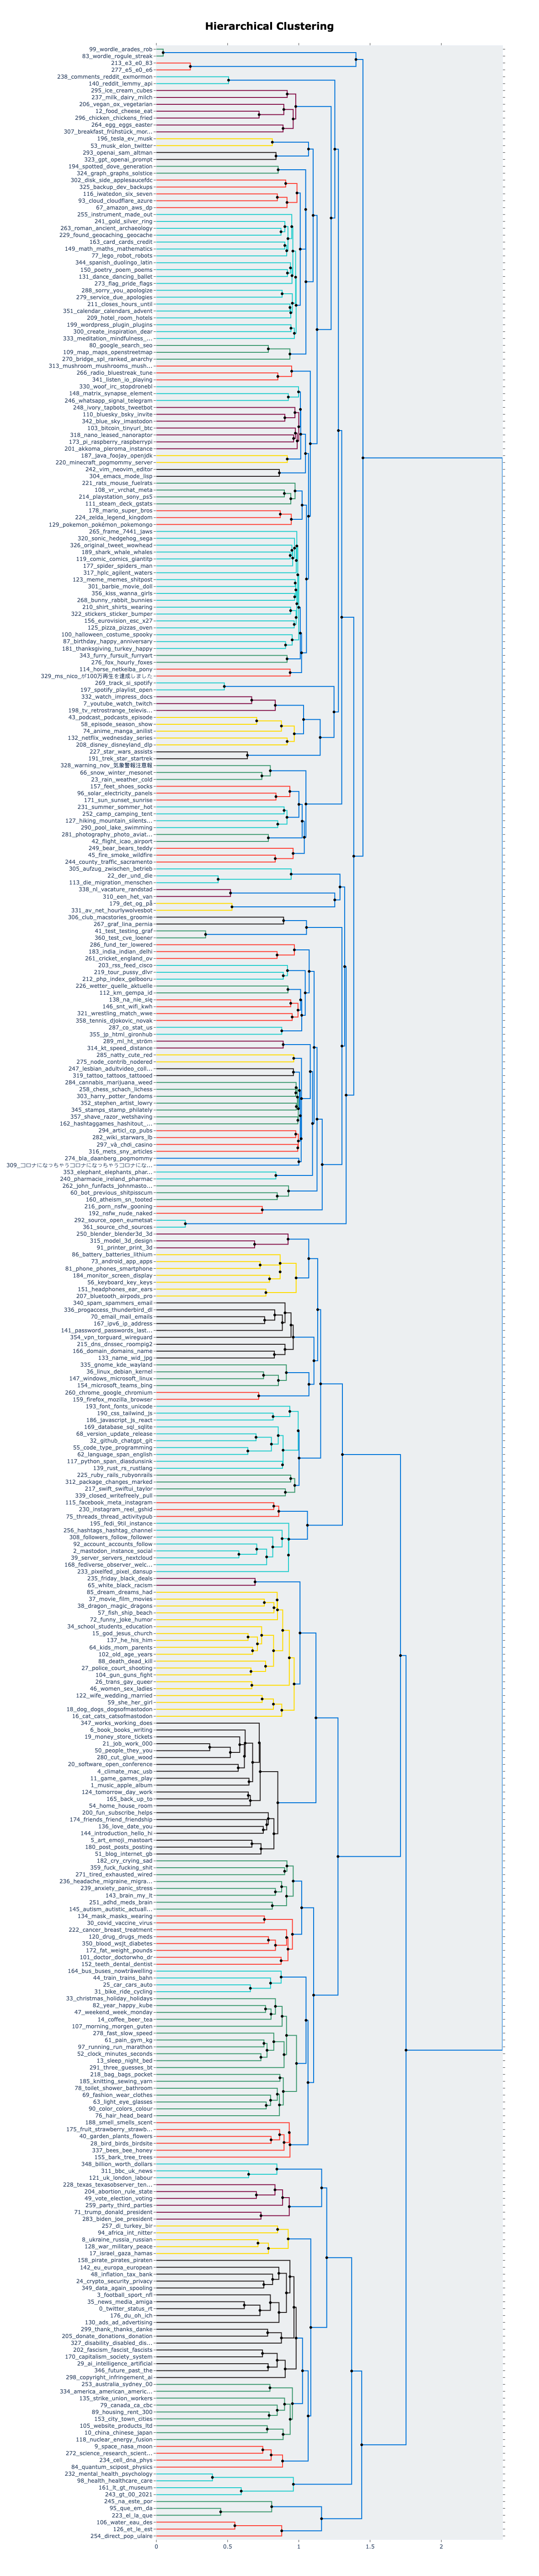

In [38]:
topic_model.visualize_hierarchy(hierarchical_topics=hierarchical_topics)

In [39]:
tree = topic_model.get_topic_tree(hierarchical_topics)
print(tree)

.
├─die_und_der_youtube_das
│    ├─wordle_e0_e5_e6_b0
│    │    ├─wordle_arades_rogule_streak_word
│    │    │    ├─■──wordle_arades_rob_ўордлі_hapi841 ── Topic: 99
│    │    │    └─■──wordle_rogule_streak_word_arades ── Topic: 83
│    │    └─e0_e5_e6_b0_e3
│    │         ├─■──e3_e0_83_81_82 ── Topic: 213
│    │         └─■──e5_e0_e6_b0_e8 ── Topic: 277
│    └─die_und_der_youtube_das
│         ├─youtube_watch_com_tv_the
│         │    ├─youtube_watch_com_tv_google
│         │    │    ├─google_akkoma_woof_musk_wordpress
│         │    │    │    ├─reddit_comments_exmormon_lemmy_subreddit
│         │    │    │    │    ├─■──comments_reddit_exmormon_diablo4_subreddit ── Topic: 238
│         │    │    │    │    └─■──reddit_lemmy_api_omments_programmerhumor ── Topic: 140
│         │    │    │    └─google_akkoma_woof_musk_wordpress
│         │    │    │         ├─food_vegan_chicken_ice_cheese
│         │    │    │         │    ├─ice_cream_milk_cubes_chocolate
│         │    │    │         │   

In [60]:
topic_model.get_representative_docs(topic=119)

['OnePlus初のメカニカルキーボードが登場 - PC Watch pc.watch.impress.co.jp/docs/ne ws/1476852.html',
 'pc.watch.impress.co.jp/docs/ne ws/1492616.html',
 'pc.watch.impress.co.jp/docs/ne ws/1547413.html']

In [42]:
topic_model_clustered_1 = topic_model

In [53]:
topics_to_merge = [

    # noise, stopwords, artifacts
    [-1, 41, 60, 116, 133, 213, 243, 254, 267, 274, 277, 287, 289, 309,
     22, 62, 95, 126, 138, 176, 179, 223, 245, 257, 310],

    # social networks / fediverse
    [0, 2, 35, 51, 75, 92, 110, 115, 140, 168, 180, 195, 201,
     230, 233, 246, 248, 256, 262, 308],

    # science, education, research
    [34, 84, 149, 161, 234, 263, 272],

    # climate, weather, environment
    [23, 40, 45, 66, 96, 106, 112, 118, 127, 155, 171, 226, 231, 290, 313],

    # neurodivergence + mental & physical health
    [30, 98, 120, 134, 143, 145, 152, 182, 222, 232, 236, 239, 240, 251],

    # queer, gender, identity, society
    [26, 46, 59, 65, 102, 122, 136, 137, 174, 273],

    # food & cooking
    [12, 125, 175, 181, 206, 237, 264, 295, 296, 307],

    # drinks & Genussmittel
    [14],

    # animals
    [16, 18, 28, 57, 114, 177, 189, 194, 221, 249, 268, 285],

    # AI / future tech
    [29, 84, 108, 293],

    # politics, geopolitics, society, capitalism
    [8, 17, 27, 49, 71, 79, 94, 113, 121, 128, 142, 183,
     202, 204, 228, 259, 283],

    # journalism & news media
    [35, 79, 94, 276, 311],

    # software, IT, programming, infrastructure
    [20, 32, 36, 39, 55, 68, 73, 91, 93, 133, 141, 147, 148,
     154, 159, 166, 167, 169, 173, 186, 187, 190, 199,
     203, 212, 215, 242, 275, 302, 304, 312],

    # music & audio
    [1, 43, 131, 156, 197, 266, 269],

    # books, poetry, writing
    [6, 150],

    # art, design, photography
    [5, 90, 119, 185, 193, 250, 281, 294, 300],

    # movies & series
    [7, 37, 58, 101, 132, 191, 198, 227, 282, 301],

    # games (video & board)
    [11, 83, 99, 111, 129, 178, 214, 220, 224, 258],

    # sports & fitness
    [3, 61, 97, 172, 261],

    # travelling & mobility
    [42, 44, 57, 164, 209, 229, 244, 252, 253, 305, 314],

    # everyday life, family, meta
    [13, 47, 50, 52, 54, 64, 76, 78, 82, 85, 87,
     100, 107, 124, 165, 176, 181, 271, 288, 299],

    # economics, finance, work
    [19, 21, 48, 82, 89, 130, 135, 163, 170, 205, 235, 286],

    # nsfw
    [192, 216, 219, 247],

    # humor & memes
    [72, 123, 200, 291],
]